# Step 1 — the plain network (no physics yet)

This is rung **A0** of the ablation ladder: an ordinary neural network,
`cycle number -> capacity`, trained with plain mean-squared-error. No SEI
equation, no film thickness, no physics loss term.

**Why build this first:** it is not throwaway scaffolding. It is the
control group. Once the physics-informed version exists, the entire
argument for adding physics rests on this notebook's numbers being worse.
If we skip this step, "the physics helped" is a claim with no baseline to
compare against.

**What it will predict well:** the shape of the curve *inside* the range it
was trained on.

**What it has no reason to get right:** anything about cycles it never
saw — because nothing tells it capacity should keep decreasing, that decay
should follow any particular rate, or that the curve shouldn't do
something strange once the data stops. That gap is the thing physics is
for, and this notebook is designed to make the gap visible.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("repo:", REPO)

repo: c:\Users\wiece\OneDrive\Desktop\FaradayX\GrunussWorkspace\PaaS4Bat_PINN_CaseStudy_YourName


## 1. Load the data

Two columns matter for this first step: `cycle` and `capacity_ah`. Everything
else in `clean_data.csv` (rest hours, temperature, ...) is set aside until the
physics stage.

In [2]:
DATA = REPO / "data" / "processed" / "clean_data.csv"
df = pd.read_csv(DATA, sep=";").sort_values("cycle").reset_index(drop=True)

print(df.shape)
df[["cycle", "capacity_ah", "soh"]].head()

(131, 11)


,cycle,capacity_ah,soh
0,2,1.843196,0.993634
1,3,1.839602,0.991697
2,4,1.830674,0.986884
3,5,1.832700,0.987976
4,6,1.828529,0.985727


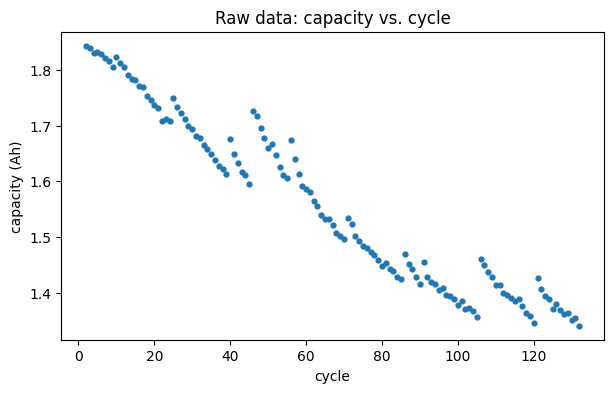

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(df.cycle, df.capacity_ah, s=12)
plt.xlabel("cycle"); plt.ylabel("capacity (Ah)")
plt.title("Raw data: capacity vs. cycle")
plt.show()

## 2. Split — train on the past, test on the future

The split is **contiguous by cycle**, not random. A random split would let
the network see cycle 120 during training and then get "tested" on cycle
90 — that is interpolation dressed up as prediction, and it would make a
bad model look good. Real deployment means: you have cycles 2–90, and you
need to say something about cycles 91 onward.

This matches the evaluation protocol already fixed in the design doc
(`docs/sei_cycle_pinn_design.html`, §8): train on cycles 2–90, hold out
91–132.

In [4]:
train_df = df[df.cycle <= 90].reset_index(drop=True)
test_df = df[df.cycle > 90].reset_index(drop=True)

print(f"train: {len(train_df)} cycles (2-90)")
print(f"test:  {len(test_df)} cycles (91-132)")

train: 89 cycles (2-90)
test:  42 cycles (91-132)


## 3. Normalise the input

The network is fed `cycle / cycle_max` rather than the raw cycle number
(2, 3, ... 132). A `tanh` network fed raw values in the hundreds saturates
on the very first layer and stops learning — everything downstream sees
the same "very large" input regardless of the actual cycle. Squashing to
roughly `[0, 1]` keeps the network in the part of `tanh` that actually has
a slope.

`cycle_max` is fixed using the **training** data only, so the test split
is never used to decide anything about how the model is built or scaled.

In [5]:
n_max = train_df.cycle.max()

x_train = torch.tensor(train_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
y_train = torch.tensor(train_df.capacity_ah.values, dtype=torch.float32).reshape(-1, 1)

x_test = torch.tensor(test_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(test_df.capacity_ah.values, dtype=torch.float32).reshape(-1, 1)

print("x_train range:", x_train.min().item(), "to", x_train.max().item())
print("x_test  range:", x_test.min().item(), "to", x_test.max().item(), " <- beyond 1.0: genuine extrapolation")

x_train range: 0.02222222276031971 to 1.0
x_test  range: 1.0111111402511597 to 1.4666666984558105  <- beyond 1.0: genuine extrapolation


## 4. The network

Four linear layers, `tanh` in between, one number in and one number out.
This is deliberately the same shape used later for the physics-informed
version, so that any difference in results comes from the *loss*, not from
a bigger or smaller network.

| Layer | Shape | Activation |
|---|---|---|
| input | `(N, 1)` | — |
| Linear | `1 -> 32` | tanh |
| Linear | `32 -> 32` | tanh |
| Linear | `32 -> 32` | tanh |
| Linear | `32 -> 1` | — (raw output = predicted capacity) |

Nothing here knows this is a battery. It is a generic curve-fitter.

In [6]:
net = nn.Sequential(
    nn.Linear(1, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 32), nn.Tanh(),
    nn.Linear(32, 1),
)
print(net)
print("trainable parameters:", sum(p.numel() for p in net.parameters()))

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): Tanh()
  (4): Linear(in_features=32, out_features=32, bias=True)
  (5): Tanh()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
trainable parameters: 2209


## 5. Train — plain mean-squared-error, nothing else

$$L = \frac{1}{N}\sum_i \bigl(\hat Q(n_i) - Q_i\bigr)^2$$

That is the entire loss. Every 500 epochs we print the training loss so you
can see it settle.

In [7]:
opt = torch.optim.Adam(net.parameters(), lr=5e-3)
epochs = 3000

history = []
for epoch in range(epochs):
    opt.zero_grad()
    pred = net(x_train)
    loss = torch.mean((pred - y_train) ** 2)
    loss.backward()
    opt.step()

    if epoch % 500 == 0 or epoch == epochs - 1:
        history.append((epoch, loss.item()))
        print(f"epoch {epoch:5d}   train MSE {loss.item():.6f}")

epoch     0   train MSE 3.310967
epoch   500   train MSE 0.000881
epoch  1000   train MSE 0.000829
epoch  1500   train MSE 0.000789
epoch  2000   train MSE 0.000764
epoch  2500   train MSE 0.000739
epoch  2999   train MSE 0.000547


## 6. Look at the fit — inside the training range, and beyond it

Two things to look at separately:

- **Inside cycles 2–90 (solid line region):** should track the data closely
  — this is the easy part, plain curve-fitting.
- **Beyond cycle 90 (shaded region):** this is genuine extrapolation. The
  network has never seen a capacity value or a cycle number in this range.
  Whatever it does here is a side-effect of the shapes `tanh` layers happen
  to produce — not a prediction grounded in anything about how batteries
  degrade.

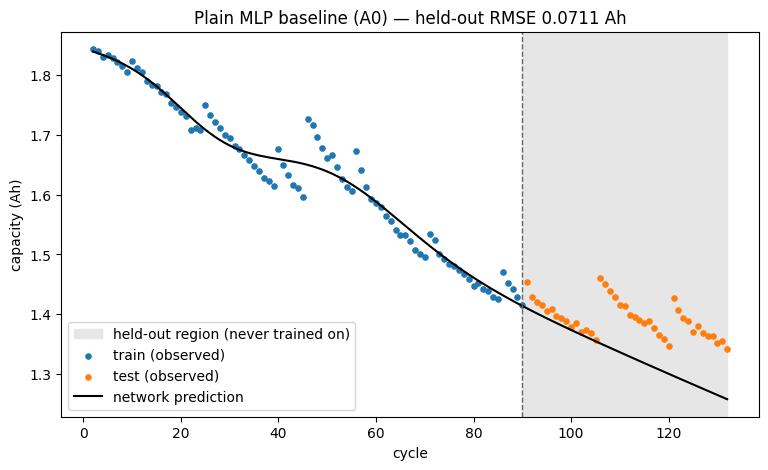

held-out RMSE: 0.0711 Ah
held-out MAE : 0.0602 Ah
for reference, capacity spans only 0.5021 Ah over the whole dataset


In [8]:
with torch.no_grad():
    x_all = torch.tensor(df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
    pred_all = net(x_all).squeeze().numpy()
    pred_test = net(x_test).squeeze().numpy()

test_rmse = float(np.sqrt(np.mean((pred_test - y_test.squeeze().numpy()) ** 2)))
test_mae = float(np.mean(np.abs(pred_test - y_test.squeeze().numpy())))

plt.figure(figsize=(9, 5))
plt.axvspan(90, df.cycle.max(), color="0.9", label="held-out region (never trained on)")
plt.scatter(train_df.cycle, train_df.capacity_ah, s=14, color="tab:blue", label="train (observed)")
plt.scatter(test_df.cycle, test_df.capacity_ah, s=14, color="tab:orange", label="test (observed)")
plt.plot(df.cycle, pred_all, color="black", lw=1.5, label="network prediction")
plt.axvline(90, color="0.4", ls="--", lw=1)
plt.xlabel("cycle"); plt.ylabel("capacity (Ah)")
plt.title(f"Plain MLP baseline (A0) — held-out RMSE {test_rmse:.4f} Ah")
plt.legend()
plt.show()

print(f"held-out RMSE: {test_rmse:.4f} Ah")
print(f"held-out MAE : {test_mae:.4f} Ah")
print(f"for reference, capacity spans only {df.capacity_ah.max()-df.capacity_ah.min():.4f} Ah over the whole dataset")

## 7. What this number means

The held-out RMSE printed above is the number every later model has to
beat. If the physics-informed version cannot do meaningfully better than
this plain network on the *same* held-out cycles, the physics term is not
earning its keep.

Two honest readings of a bad result here, and they point to different
fixes:

- **The curve wiggles or flattens oddly past cycle 90** — expected. Nothing
  told the network capacity should keep falling. This is precisely the gap
  the SEI growth law is meant to fill.
- **The fit inside 2–90 is also poor** — that would be a genuine problem
  with the network itself (too small, too few epochs, bad learning rate),
  independent of physics. Worth checking before blaming the missing
  physics term for everything.

## 8. Why `tanh`, and what happens with `ReLU`

Every layer above used `tanh` as the activation. The obvious question:
does the choice matter, and would `ReLU` do better?

For this notebook — plain curve-fitting, no physics — the answer is:
`ReLU` can genuinely win. It bends sharply where `tanh` bends smoothly,
which suits a curve like this one that isn't smooth in any special way.

The reason `tanh` was picked anyway is a constraint from the *next*
notebook, not this one. The physics loss needs a real derivative of the
network's output (`du/dcycle`), computed by autograd. `ReLU` is
piecewise-linear: its second derivative is zero almost everywhere and
undefined exactly at the kinks. That is fine for `ReLU`'s first
derivative, but the physics-informed training also backpropagates
*through* that derivative — which needs the second derivative to exist.
`tanh` is smooth everywhere, so autograd never hits a blind spot.

So this comparison exists to make that tradeoff visible, not to declare
a winner: `ReLU` for a better baseline number here, `tanh` (or another
smooth activation) once the physics term exists.

In [9]:
def build(activation):
    return nn.Sequential(
        nn.Linear(1, 32), activation(),
        nn.Linear(32, 32), activation(),
        nn.Linear(32, 32), activation(),
        nn.Linear(32, 1),
    )

results = {}
for name, activation in [("tanh", nn.Tanh), ("relu", nn.ReLU)]:
    torch.manual_seed(0)
    net_cmp = build(activation)
    opt_cmp = torch.optim.Adam(net_cmp.parameters(), lr=5e-3)

    for epoch in range(epochs):
        opt_cmp.zero_grad()
        loss_cmp = torch.mean((net_cmp(x_train) - y_train) ** 2)
        loss_cmp.backward()
        opt_cmp.step()

    with torch.no_grad():
        pred_cmp = net_cmp(x_test).squeeze().numpy()
    rmse_cmp = float(np.sqrt(np.mean((pred_cmp - y_test.squeeze().numpy()) ** 2)))
    results[name] = (net_cmp, rmse_cmp)
    print(f"{name:6s}  final train MSE {loss_cmp.item():.6f}   held-out RMSE {rmse_cmp:.4f} Ah")

tanh    final train MSE 0.000547   held-out RMSE 0.0711 Ah
relu    final train MSE 0.000356   held-out RMSE 0.0353 Ah


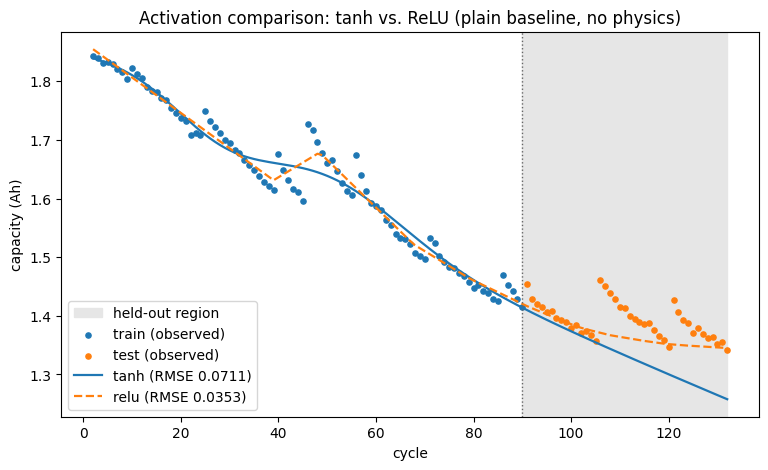

In [10]:
plt.figure(figsize=(9, 5))
plt.axvspan(90, df.cycle.max(), color="0.9", label="held-out region")
plt.scatter(train_df.cycle, train_df.capacity_ah, s=14, color="tab:blue", label="train (observed)")
plt.scatter(test_df.cycle, test_df.capacity_ah, s=14, color="tab:orange", label="test (observed)")

with torch.no_grad():
    for name, style in [("tanh", "-"), ("relu", "--")]:
        model_cmp, rmse_cmp = results[name]
        pred_all_cmp = model_cmp(x_all).squeeze().numpy()
        plt.plot(df.cycle, pred_all_cmp, style, lw=1.6,
                 label=f"{name} (RMSE {rmse_cmp:.4f})")

plt.axvline(90, color="0.4", ls=":", lw=1)
plt.xlabel("cycle"); plt.ylabel("capacity (Ah)")
plt.title("Activation comparison: tanh vs. ReLU (plain baseline, no physics)")
plt.legend()
plt.show()

## What comes next

The next notebook keeps this exact same network shape and swaps two
things: the output stops being capacity directly and becomes a physical
quantity (film thickness), and the loss gains a second term that penalises
the network for disagreeing with the SEI growth equation. Same weights,
same optimiser — only the loss and what the output *means* changes.

Because of the second-derivative requirement above, that notebook keeps
`tanh` as the activation regardless of which one wins the comparison
here.